# JS11 - Praktikum 3: SVM Data Overlapping & Parameter C
**Mata Kuliah:** Pembelajaran Mesin  
**Nama:** Aryaputra | **NIM:** 244107020127  

---
### Deskripsi
Mempelajari pengaruh parameter regularisasi $C$ pada data yang saling tumpang tindih (*soft margin* vs *hard margin*).


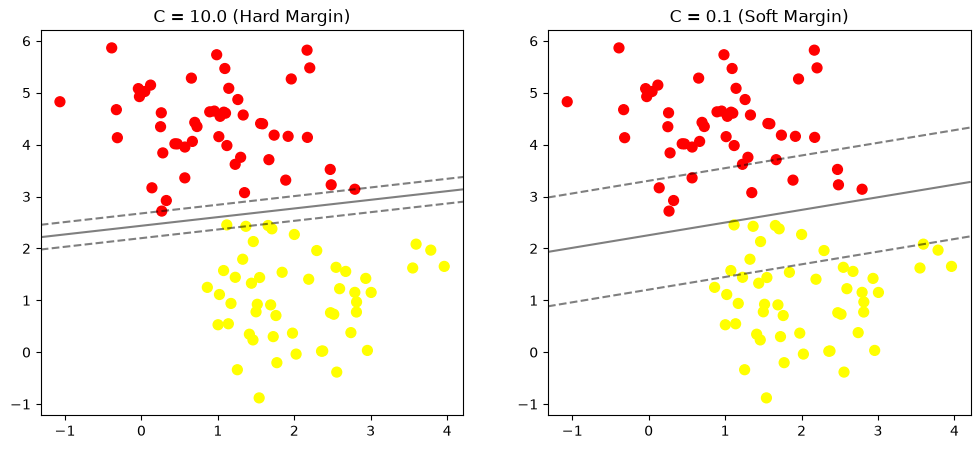

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.svm import SVC

X, y = make_blobs(n_samples=100, centers=2, random_state=0, cluster_std=0.8)

def plot_svc(model, ax):
    xlim, ylim = ax.get_xlim(), ax.get_ylim()
    x = np.linspace(xlim[0], xlim[1], 30)
    y_l = np.linspace(ylim[0], ylim[1], 30)
    Y, X_g = np.meshgrid(y_l, x)
    P = model.decision_function(np.vstack([X_g.ravel(), Y.ravel()]).T).reshape(X_g.shape)
    ax.contour(X_g, Y, P, colors='k', levels=[-1, 0, 1], alpha=0.5, linestyles=['--', '-', '--'])

fig, ax = plt.subplots(1, 2, figsize=(12, 5))
for axi, C in zip(ax, [10.0, 0.1]):
    model = SVC(kernel='linear', C=C).fit(X, y)
    axi.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
    plot_svc(model, axi)
    axi.set_title(f'C = {C} ({"Hard Margin" if C==10 else "Soft Margin"})')
plt.show()
